# Singular Value Decomposition (SVD)

## Recap: where we left off

- In the KNN notebook, we saw the **curse of dimensionality**: our feature matrix has dozens of columns (13 numeric features and 51 one-hot dummies), and distances become less informative as dimensions are added
- That notebook ended by saying the problem is dealt with by **reducing the number of dimensions**. This notebook does that

## Why reduce dimensions?

- Many features carry overlapping information. Debt amounts, days past due and missed payments move together
- SVD finds a small number of new features, called **latent features**, that capture most of the variation in the original ones
- The result is a compact description of each account. The reinforcement learning notebook uses the top 5 components as part of its state vector

## The SVD theorem

Let $M$ be an $m \times n$ matrix of rank $r$. Then:

$$ M = U \Sigma V^T, $$

where

- $U$ is an $m \times r$ column-orthonormal matrix
- $V$ is an $n \times r$ column-orthonormal matrix
- $\Sigma$ is an $r \times r$ diagonal matrix containing the **singular values**, ordered from largest to smallest

For our data, $M$ has one row per account and one column per feature, so $m$ is the number of accounts and $n = 64$.

- Each **singular value** tells how much of the variation the corresponding component captures
- $V^T$ tells how each component is built from the original features
- $U \Sigma$ holds the new, reduced coordinates of every account

## What this notebook does

- Standardises the feature matrix and fits SVD on **train only**
- Computes the full SVD and looks at the singular values
- Chooses how many components to keep
- Applies the truncated SVD, which keeps only the largest components
- Plots the accounts in 2D and interprets the components
- Saves the top 5 components for the reinforcement learning notebook

Documentation: [numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)  
Documentation: [sklearn TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)

## 1. Setup and Data Preparation

### 1.1 Imports and loading the data

In [1]:
import pandas as pd                 # DataFrame operations: loading, filtering, joining
import numpy as np                  # numeric arrays and math
import matplotlib.pyplot as plt     # base plotting
import seaborn as sns               # statistical plots built on matplotlib
import scipy                        # imported only to print its version
import sklearn                      # imported only to print its version
from scipy.linalg import svd                    # the full SVD of a matrix
from sklearn.decomposition import TruncatedSVD  # the truncated SVD: only the largest components

# Record the versions, so results can be tied to a setup
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scipy:', scipy.__version__, '| scikit-learn:', sklearn.__version__)

# Load the feature matrix produced by the EDA notebook. One row per account,
# features and all five targets already joined, split label already assigned
DATA_DIR = "data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

print()
print(f'Loaded: {master.shape[0]:,} rows, {master.shape[1]} columns')
print()
print('Split sizes:')
print(master['split'].value_counts())

pandas: 3.0.3 | numpy: 2.4.6 | scipy: 1.18.1 | scikit-learn: 1.9.1

Loaded: 13,945 rows, 31 columns

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


### 1.2 Preparing the feature matrix

Same steps as in the earlier notebooks, in one cell:

- Drop the accounts with no split assigned, and one-hot encode the nominal columns, with the encoder **fit on train only**
- Define the feature set (64 columns) and drop the few rows with missing values. SVD cannot handle `NaN`
- **Standardise** every feature, with the scaler **fit on train only**. SVD is sensitive to scale: a feature with large values would dominate the first components
- After standardising, every column has mean 0 on train. `TruncatedSVD` does not centre the data itself, so on this matrix it is equivalent to **PCA** on the train rows
- **Fit on train only:** the components are learned from train and then applied to validation and test, so no information from the later periods leaks in

In [2]:
##########################################################
## Prepare the feature matrix                            ##
##########################################################
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # OneHotEncoder: dummy columns; StandardScaler: mean 0 and std 1

# --- Drop accounts with no split assigned ---
master = master[master['split'] != 'unknown'].copy()  # they cannot be assigned to train, validation or test

# --- One-hot encode the remaining nominal variables ---
nominal_cols = ['debt_type', 'status', 'city', 'gender', 'household_type',
                'employment_status', 'urban_category', 'country_of_origin',
                'born_in_netherlands']
nominal_cols = [c for c in nominal_cols if c in master.columns]  # keep only columns that exist, avoids a KeyError

# Fit the encoder on the train rows only. fillna('unknown').astype(str) gives
# every missing value an explicit category and avoids mixing bool with str
train_data = master[master['split'] == 'train']
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
enc.fit(train_data[nominal_cols].fillna('unknown').astype(str))

# Apply the train-fitted encoder to the full table (train + val + test)
encoded = enc.transform(master[nominal_cols].fillna('unknown').astype(str))
encoded_cols = enc.get_feature_names_out(nominal_cols)  # names like 'debt_type_Credit card'

# Attach the dummy columns to master, keeping master's index so rows line up
encoded_df = pd.DataFrame(encoded, columns=list(encoded_cols), index=master.index)
master = pd.concat([master, encoded_df], axis=1)

# --- Define the feature set ---
numeric_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'income_band_encoded', 'education_level_encoded',
                    'balance_capped', 'default_date_imputed']
dummy_features = list(encoded_cols)               # one-hot dummy columns
feature_cols = numeric_features + dummy_features  # the full feature list: IDs, split and targets are left out

# --- Drop rows with missing feature values (under 1% of every split) ---
rows_before = len(master)
master = master.dropna(subset=feature_cols).copy()  # drop rows with any missing feature value
print(f'Dropped {rows_before - len(master)} rows with missing feature values')

# --- The original splits, as assigned in the EDA notebook ---
df_train = master[master['split'] == 'train']  # the components are learned from these rows
df_val   = master[master['split'] == 'val']    # the components are applied to these rows
df_test  = master[master['split'] == 'test']   # and to these rows

X_train = df_train[feature_cols]  # train features, unscaled
X_val   = df_val[feature_cols]    # validation features, unscaled
X_test  = df_test[feature_cols]   # test features, unscaled

# --- Standardise: fit on train only, then apply to all three ---
scaler = StandardScaler()
scaler.fit(X_train)  # fit on train only, same rule as every other transform in this project

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feature_cols, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),   columns=feature_cols, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=feature_cols, index=X_test.index)

print(f'Features: {len(feature_cols)}')
print(f'X_train_scaled: {X_train_scaled.shape}, X_val_scaled: {X_val_scaled.shape}, X_test_scaled: {X_test_scaled.shape}')

Dropped 109 rows with missing feature values
Features: 64
X_train_scaled: (8894, 64), X_val_scaled: (3090, 64), X_test_scaled: (1537, 64)


**QUESTIONS:**

- We standardise every column, including the one-hot dummies. What does that do to the values of a rare category (a dummy that is 1 for only 2% of the accounts)? Would you treat the dummies differently from the numeric features?
- The pickle holds only part of what we know about a debtor: for example `city` but not the postcode, and nothing about the debtor's other accounts. What is left out, and how could it change what SVD finds?

## 2. The Full SVD

We compute the full SVD of the **standardised train matrix** $M$, with 8,894 accounts (rows) and 64 features (columns), and look at the three matrices.

- `scipy.linalg.svd` returns $U$, the singular values as a vector, and $V^T$
- `full_matrices=False` returns the compact form, with $r$ columns in $U$ instead of one for every account
- We check the theorem by multiplying the three matrices back together

In [3]:
##########################################################
## The full SVD of the standardised train matrix         ##
##########################################################
M = X_train_scaled.to_numpy()  # the matrix to decompose: one row per account, one column per feature

U, s, V_T = svd(M, full_matrices=False)  # U: left singular vectors, s: the singular values, V_T: right singular vectors
Sigma = np.diag(s)                       # the singular values as a diagonal matrix

print('Dimensions of the original matrix M:   ', M.shape)
print('Dimensions of the U matrix:            ', U.shape)
print('Dimensions of the Sigma diagonal matrix:', Sigma.shape)
print('Dimensions of the V^T matrix:          ', V_T.shape)

# Check the theorem: U Sigma V^T should give back M, up to rounding error
M_back = U @ Sigma @ V_T
print()
print('U Sigma V^T equals M:', np.allclose(M, M_back))

# The singular values come ordered from largest to smallest
print()
print('Largest 5 singular values: ', np.round(s[:5], 1))
print('Smallest 5 singular values:', np.round(s[-5:], 4))

Dimensions of the original matrix M:    (8894, 64)
Dimensions of the U matrix:             (8894, 64)
Dimensions of the Sigma diagonal matrix: (64, 64)
Dimensions of the V^T matrix:           (64, 64)

U Sigma V^T equals M: True

Largest 5 singular values:  [166.3 151.3 148.2 141.9 135.4]
Smallest 5 singular values: [10.6181  0.      0.      0.      0.    ]


**QUESTIONS:**

- What does each dimension of `U`, `Sigma` and `V_T` stand for: accounts, features or components? Which of the three matrices holds the new coordinates of an account, and which one says how a component is built from the original features?
- What would the shape of `U` be with `full_matrices=True`? Why is the compact form enough for us?
- The singular values are ordered from largest to smallest. Look at the smallest values. What would a singular value of exactly 0 tell you about the columns of the matrix? Does any column of ours behave like that?
- Multiplying the three matrices back gives `M`. What would happen if you multiplied only the first $k$ columns of $U$, the first $k$ singular values, and the first $k$ rows of $V^T$?

## 3. Singular Values and the Number of Components

### 3.1 Explained variance

- The squared singular value $\sigma_i^2$ measures how much of the total variation component $i$ captures. The **share of variance explained** by component $i$ is:

$$\text{explained variance ratio}_i = \frac{\sigma_i^2}{\sum_j \sigma_j^2}$$

- The **cumulative** explained variance adds these shares up from the first component
- A **scree plot** shows the singular values, or their shares, in order. Components after the point where the curve flattens add little
- **Two common rules for choosing the number of components $k$:**
  - **Elbow:** keep the components before the curve flattens
  - **Threshold:** keep the smallest $k$ whose cumulative explained variance reaches a threshold, such as 95%
- The choice is a trade-off between a compact representation and the information lost. 95% is a convention, not a law
- We use the singular values `s` from Section 2, which came from the **train** matrix only

Components needed for 95% of the variance: 48
Variance explained by the first 5 components:  19.8%
Variance explained by the first 10 components: 32.9%


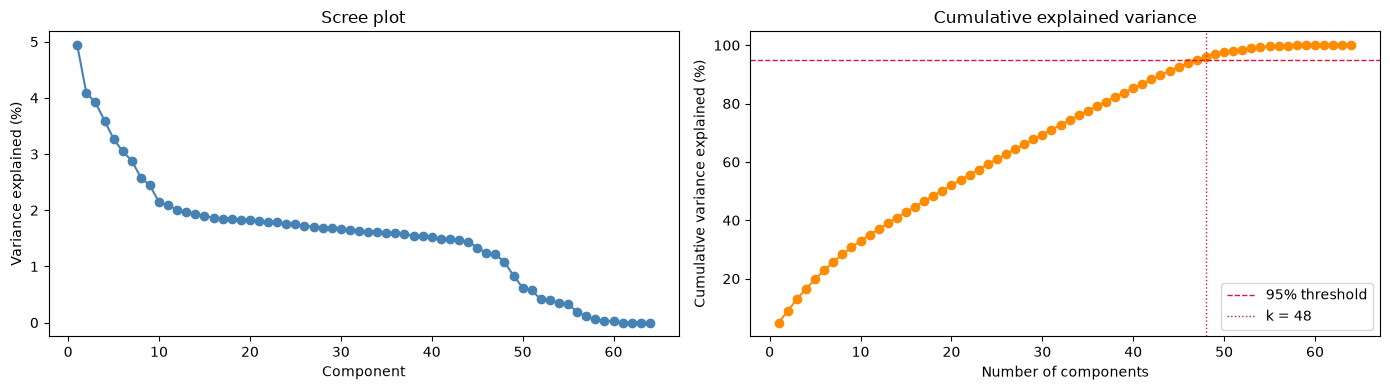

In [7]:
##########################################################
## Explained variance, the scree plot and the threshold  ##
##########################################################
variance_ratio = s ** 2 / np.sum(s ** 2)   # share of the total variance held by each component
cumulative = np.cumsum(variance_ratio)     # running total of the shares

threshold = 0.95                                              # the threshold for the cumulative explained variance
k_threshold = int(np.argmax(cumulative >= threshold)) + 1     # first number of components that reaches it, +1 because we count from 1

print(f'Components needed for {threshold:.0%} of the variance: {k_threshold}')
print(f'Variance explained by the first 5 components:  {cumulative[4]:.1%}')
print(f'Variance explained by the first 10 components: {cumulative[9]:.1%}')

components = np.arange(1, len(s) + 1)   # 1, 2, ..., 64: the component numbers for the x-axis

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: the scree plot, the share of variance of every component
axes[0].plot(components, variance_ratio * 100, marker='o', color='steelblue')
axes[0].set_xlabel('Component')
axes[0].set_ylabel('Variance explained (%)')
axes[0].set_title('Scree plot')

# Right: the cumulative share, with the threshold and the number of components that reaches it
axes[1].plot(components, cumulative * 100, marker='o', color='darkorange')
axes[1].axhline(threshold * 100, color='crimson', linestyle='--', linewidth=1, label=f'{threshold:.0%} threshold')
axes[1].axvline(k_threshold, color='crimson', linestyle=':', linewidth=1, label=f'k = {k_threshold}')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative variance explained (%)')
axes[1].set_title('Cumulative explained variance')
axes[1].legend()

plt.tight_layout()
plt.show()

**QUESTIONS:**

- How many components are needed to reach 95% of the variance? What share do the first 5 and the first 10 hold? Is that a strong compression of 64 features?
- Look at the scree plot. Is there a clear elbow? What would the plot look like for a dataset in which the features are strongly correlated?
- The singular values were close together in Section 2. What does that say about how much the 64 columns overlap? Think about how many of them are one-hot dummies
- The elbow rule and the threshold rule may give different values of $k$. Which would you choose, and why? Try 90% and 99%. How does $k$ change?
- The explained variance here comes from the train matrix. Project the validation rows on the components and compute the share of their variance that the first $k$ components explain. How does it compare with train?

## 4. Truncated SVD

### 4.1 How many components for each threshold?

Before we fix $k$, we look at the trade-off between the number of components and the variance kept, for several thresholds.

In [8]:
##########################################################
## Number of components for several thresholds           ##
##########################################################
thresholds = [0.50, 0.80, 0.90, 0.95, 0.99]   # cumulative explained variance levels to compare

rows = []                                              # one row per threshold
for th in thresholds:                                  # loop over the thresholds
    k_th = int(np.argmax(cumulative >= th)) + 1        # first number of components that reaches the threshold, +1 because we count from 1
    rows.append({'threshold': th, 'components': k_th})

pd.DataFrame(rows)  # cumulative comes from Section 3

,threshold,components
0,0.50,19
1,0.80,37
2,0.90,44
3,0.95,48
4,0.99,54


### 4.2 The truncated SVD

The truncated SVD keeps only the $k$ largest components, which gives a low-rank approximation of the matrix $X$ with $n$ features ($k < n$):

$$ X \approx X_k = U_k \Sigma_k V^T_k $$

- $U_k \Sigma_k$ is the **reduced data**, with $k$ columns instead of 64
- `TruncatedSVD` is **fit on train**, which learns $V_k$. The validation and test rows are then **projected** onto the same components, with `transform`
- We keep the number of components that reaches the 95% threshold, `k_threshold` from Section 3
- `TruncatedSVD` does not centre the data. Our matrix is already standardised with the train means, so this is not a problem here

In [10]:
##########################################################
## Fit the truncated SVD on train, project all splits    ##
##########################################################
# n_components: how many singular values to keep, n_iter and random_state: settings of the randomised solver
svd_trunc = TruncatedSVD(n_components=k_threshold, n_iter=7, random_state=42)

X_train_svd = svd_trunc.fit_transform(X_train_scaled)  # fit on train only, and return the reduced train data
X_val_svd   = svd_trunc.transform(X_val_scaled)        # project validation onto the components learned from train
X_test_svd  = svd_trunc.transform(X_test_scaled)       # project test onto the same components

print('X_train_scaled:              ', X_train_scaled.shape)             # the original matrix
print('X_train_svd:                 ', X_train_svd.shape)                # the reduced data
print('svd_trunc.components_:       ', svd_trunc.components_.shape)      # the matrix V_k^T
print('svd_trunc.singular_values_:  ', svd_trunc.singular_values_.shape) # the k largest singular values

# Compare with the full SVD of Section 2: the largest difference between the first k singular values
print('Largest difference with the full SVD:', np.max(np.abs(svd_trunc.singular_values_ - s[:k_threshold])))

X_train_scaled:               (8894, 64)
X_train_svd:                  (8894, 48)
svd_trunc.components_:        (48, 64)
svd_trunc.singular_values_:   (48,)
Largest difference with the full SVD: 3.410605131648481e-13


**QUESTIONS:**

- Look at the table in 4.1. How many components do 50%, 80%, 90%, 95% and 99% of the variance need? Which would you use as input for a reinforcement learning state vector, and why?
- What are the arrays whose shapes are printed? What does each dimension stand for: accounts, components or features?
- How can you get the approximation of the original matrix back from `svd_trunc`? Compute it for the train rows. How does the reconstruction error relate to the 5% of the variance that we did not keep?
- We used `fit_transform` on train and only `transform` on validation and test. Why do we not fit on all the rows?
- Compare `svd_trunc.singular_values_` with the first 48 singular values of the full SVD in Section 2. Are they exactly the same? Look at the `algorithm` and `n_iter` arguments in the documentation to explain any difference
- Each column of `X_train_svd` is a weighted sum of all 64 features. Which array holds the weights?
- `sklearn.decomposition.PCA` is closely related. How does it differ from `TruncatedSVD`, and when would the two give the same result?

## 5. Looking at the Components

### 5.1 The accounts in 2D

We plot every train account on the **first two components**, once coloured by `debt_type` and once by `city`. The coordinates are the first two columns of the reduced data.

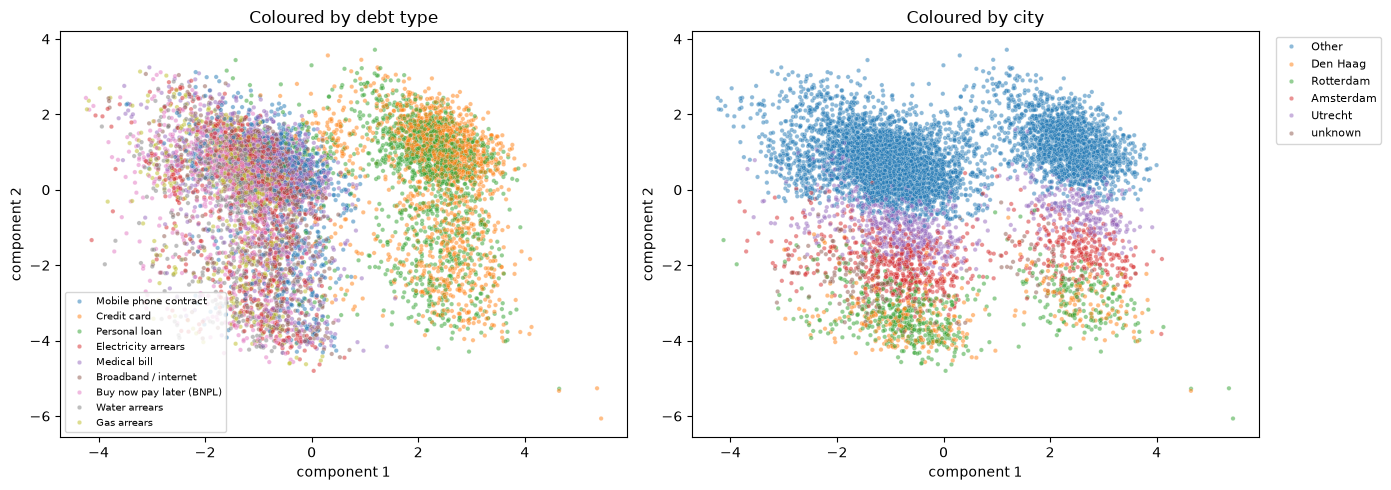

Variance explained by the first two components: 9.0%


In [14]:
##########################################################
## The accounts in 2D: the first two components          ##
##########################################################
plot_df = pd.DataFrame({'component 1': X_train_svd[:, 0],                      # coordinate on the first component
                        'component 2': X_train_svd[:, 1],                      # coordinate on the second component
                        'debt_type': df_train['debt_type'].to_numpy(),         # colour for the left plot
                        'city': df_train['city'].fillna('unknown').to_numpy()})  # colour for the right plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: coloured by debt type
sns.scatterplot(data=plot_df, x='component 1', y='component 2', hue='debt_type', s=10, alpha=0.5, ax=axes[0])
axes[0].set_title('Coloured by debt type')
axes[0].legend(fontsize=7)

# Right: coloured by city
sns.scatterplot(data=plot_df, x='component 1', y='component 2', hue='city', s=10, alpha=0.5, ax=axes[1])
axes[1].set_title('Coloured by city')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)  # place the legend outside the plot, to the right

plt.tight_layout()
plt.show()

print(f'Variance explained by the first two components: {cumulative[1]:.1%}')  # cumulative comes from Section 3

**QUESTIONS:**

- Do the accounts form groups? Along which axis does debt type separate them, and along which does city? What do you conclude about the two components?
- The printed line gives the share of the variance that the two components hold. How much can you trust structure in a view that shows only that share?
- The points form separate blocks. What in the data could cause that? Think about the one-hot dummies
- The sign of a component is arbitrary: multiplying a column of $U$ and the matching row of $V^T$ by -1 gives the same decomposition. What does that mean for reading the axes?
- Compare the plot with the loadings you print in 5.2. Do the groups you see match the features with the largest loadings?
- Colour the same plot by `repayment_probability`. Do the first two components separate repayers from non-repayers?

### 5.2 Interpreting the components

- Each row of `svd_trunc.components_` (the matrix $V_k^T$) belongs to one component, and holds one **loading** per original feature
- A component's coordinate for an account is the **weighted sum** of the account's standardised features, with the loadings as weights. A feature with a large loading (positive or negative) matters for that component
- The features are standardised, so loadings are comparable between features
- The loadings of one component are scaled so that their squares add up to 1
- The **sign** of a component is arbitrary. What matters is which features have loadings of the same sign, and which of the opposite sign
- We list the 8 features with the largest absolute loading for each of the first 5 components

In [13]:
##########################################################
## The features with the largest loadings per component  ##
##########################################################
loadings = pd.DataFrame(svd_trunc.components_.T, index=feature_cols)  # one row per feature, one column per component (0, 1, 2, ...)

for i in range(5):                                           # loop over the first five components
    weights = loadings[i]                                    # the loadings of component i + 1, one per feature
    order = weights.abs().sort_values(ascending=False).index  # features ordered by the size of their loading, largest first
    print(f'Component {i + 1}: the 8 features with the largest loadings')
    print(weights[order].head(8).round(3))
    print()

# The squared loadings of a component add up to 1
print('Sum of squared loadings, first 5 components:', (svd_trunc.components_ ** 2).sum(axis=1)[:5].round(3))

Component 1: the 8 features with the largest loadings
log_original_amount                   0.473
interest_rate                         0.462
log_outstanding_balance               0.409
debt_type_Credit card                 0.347
debt_type_Personal loan               0.289
debt_type_Buy now pay later (BNPL)   -0.164
status_Closed - settled              -0.156
debt_type_Water arrears              -0.137
Name: 0, dtype: float64

Component 2: the 8 features with the largest loadings
city_Other                            0.521
urban_category_Very strongly urban   -0.486
city_Rotterdam                       -0.328
city_Den Haag                        -0.254
urban_category_Weakly urban           0.228
urban_category_Non-urban              0.162
missed_payments                      -0.155
born_in_netherlands_True             -0.155
Name: 1, dtype: float64

Component 3: the 8 features with the largest loadings
born_in_netherlands_True                  0.482
country_of_origin_Dutch origin      

**QUESTIONS:**

- Look at the features with the largest loadings of component 1. What do they have in common? How would you name this component?
- Do the same for components 2 to 5. Which ones describe the debt itself, and which describe the debtor or where they live? Why must the components be orthogonal to each other?
- Compare the loadings within components 3 and 5. Do some features have exactly the same loading? What does that tell you about those columns? How does a duplicated feature affect what SVD finds, and what would you do about it?
- Which components are made up mostly of one-hot dummies, and which mostly of numeric features? What does that say about where the variance of the matrix comes from?
- A component has a loading of +0.4 on one feature and -0.4 on another. What does that say about an account with a high score on this component? What happens to this reading if you flip the sign of the whole component?
- The sum of squared loadings is 1 for every component. Why? Look at the orthonormality of the rows of $V^T$
- Could you explain a component to the debt collection agency? How would you judge whether the latent features are worth using in a model?

## 6. Saving the Embeddings

- We save the reduced data of **all three splits**, so the reinforcement learning notebook can look up an account's components. The components were learned from **train** only, and validation and test were projected onto them
- We save **every component** that reaches the threshold, ordered by singular value, so the first columns are the most important. How many components to use is decided in the reinforcement learning notebook
- The file is saved **per account**, with `account_id` as the key, because the features behind it (amounts, days past due) differ between the accounts of one debtor. `debtor_id` and `split` are saved too
- The file goes into `DATA_DIR`, next to `cleaned_dataset.pkl`
- Accounts that were dropped in 1.2 (no split assigned, or missing feature values) have no embedding. A merge in the next notebook must allow for that

In [12]:
##########################################################
## Save the embeddings for the reinforcement learning    ##
## notebook                                              ##
##########################################################
svd_columns = []                              # names of the component columns: svd_1, svd_2, ...
for i in range(k_threshold):                  # loop over the components
    svd_columns.append('svd_' + str(i + 1))   # components are counted from 1

parts = []                                    # one table per split
for split_name, X_svd, df_split in [('train', X_train_svd, df_train),
                                    ('val',   X_val_svd,   df_val),
                                    ('test',  X_test_svd,  df_test)]:
    part = pd.DataFrame(X_svd, columns=svd_columns, index=df_split.index)  # the reduced data, with the row labels of the split
    part.insert(0, 'split', split_name)                                    # the split of each account
    part.insert(0, 'debtor_id', df_split['debtor_id'])                     # the debtor of each account
    part.insert(0, 'account_id', df_split['account_id'])                   # the key, placed first
    parts.append(part)

svd_embeddings = pd.concat(parts)                     # stack train, validation and test
svd_embeddings.to_pickle(DATA_DIR + 'svd_embeddings.pkl')

# Check: load the file back and look at it
check = pd.read_pickle(DATA_DIR + 'svd_embeddings.pkl')
print('Shape:', check.shape)
print('account_id is unique:', check['account_id'].is_unique)
print(check['split'].value_counts())
check.head()

Shape: (13521, 51)
account_id is unique: True
split
train    8894
val      3090
test     1537
Name: count, dtype: int64


,account_id,debtor_id,split,svd_1,svd_2,svd_3,svd_4,svd_5,svd_6,svd_7,...,svd_39,svd_40,svd_41,svd_42,svd_43,svd_44,svd_45,svd_46,svd_47,svd_48
1,39866796-bbf7-43b7-a552-a5e4c1fb4354,aa7588f7-dd4a-4a7f-bff8-54da2fab20a2,train,0.740197,-0.545794,0.833792,4.064145,0.430633,-0.635928,-0.331982,...,-0.778740,-0.694198,-1.808878,0.764165,0.079536,-0.368575,1.185843,-0.156758,0.347736,-0.713763
3,eedc8d1a-6c22-441d-ab43-75c83467b96a,77a6c22c-dc7f-4a6f-ae7f-fe7a1b3305f5,train,2.088214,-3.351009,0.003686,-1.300317,-1.604083,-1.388854,0.420185,...,-1.826150,2.820000,2.112332,-3.020581,0.911120,0.834267,-1.898934,2.006013,-1.304428,-0.031961
4,38396424-7631-4b1c-92ce-af0ed2ad320e,4be5cd8c-959c-4765-92ac-e297f192aaf2,train,1.652945,1.381541,1.600958,-0.765548,0.368744,-0.941014,1.082369,...,-0.870930,0.770505,0.100722,-0.941624,-1.284383,1.676508,0.345504,-0.526718,0.432801,0.532900
5,4c06dbdf-94b9-4e8d-88d8-0a58e1ea96d0,4be5cd8c-959c-4765-92ac-e297f192aaf2,train,-1.262365,0.348140,1.702638,0.168992,0.341564,-1.062747,0.755871,...,0.872899,0.386095,-0.912306,0.559194,-0.521884,1.987619,0.239128,-0.169098,0.635928,0.692572
6,396c16ec-7df5-4c19-8f7f-a316c32f07ec,0ff9e539-fdfb-43be-8ad0-4042de9cd0ce,train,-0.431961,1.241352,-0.580267,1.231888,-0.177541,-0.437211,-1.985350,...,0.208142,-0.021606,-0.213370,-0.529775,-0.519361,-0.529239,-0.456449,0.551304,-0.492940,0.978710
